In [14]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))

# Now import Model from freeflux

import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import analysis.io_func as io_func
from matplotlib import ticker
## notebook where we just load previously generated csv (sampled data + weights) and plot the global flux range (va + sampling)


In [15]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [16]:
from analysis import config_pta as cfp
 ##flux bounds  
cond='TM6'

prep=cfp.config_prep(cond)

removing ['Galkin', 'Gal7', 'Gal10', 'Mankin', 'M6pism', 'MALTGD', 'gal-D_EX', 'man-D_EX', 'malt_EX', 'GALt+0', 'Mant+0', 'MALTt+1']
no met data for ppi_c 'ppi'
no met data for 4pasp_c '4pasp'
no met data for oaa_c 'oaa'
no met data for oaa_m 'oaa'
no met data for nadph_c 'nadph'
no met data for aspsa_c 'aspsa'
no met data for pi_c 'pi'
no met data for pyr_c 'pyr'
no met data for pyr_m 'pyr'
no met data for glycogen_c 'glycogen'
no met data for g1p_c 'g1p'
no met data for glx_c 'glx'
no met data for hco3_m 'hco3'
nadph_m ignored because we set constraint on redox ratio
no met data for hco3_c 'hco3'
no met data for acglu_m 'acglu'
no met data for acg5p_m 'acg5p'
no met data for acg5sa_m 'acg5sa'
no met data for acorn_m 'acorn'
no met data for argsuc_c 'argsuc'
no met data for arg-L_c 'arg-L'
no met data for citr-L_c 'citr-L'
no met data for cbp_c 'cbp'
no met data for glu5p_c 'glu5p'
no met data for pi_m 'pi'
no met data for 10fthf_c '10fthf'
no met data for thf_c 'thf'
no met data for 

load flux samples

In [17]:
samples=pd.read_csv(f'{cfp.RESULTS_FOLDER}/b3_flux_sampling/{cond}/{cond}fluxsamples.csv',index_col=0)


In [18]:
# samples.iloc[:,0].items()
samples

,ASNS1,ASPK,ASPTA,ASPTAm,ASAD,ALATA_L,ALATA_Lm,GLCS2,PGMT,GALU,...,PItm-2+2H,PItm-2+H,PItm-2,PYRtm-1,PYRtm-1+H,SUCCPItm-2-2,SUCFUMtm-2-2,THRtm+0,biomass_ce,biomass_EX
0,0.025661,0.120043,-0.037198,-0.306000,0.120043,0.160075,-0.043688,0.094756,-0.630092,0.692141,...,4.068671,14.789998,-0.163522,-0.643419,0.743440,-0.056900,-0.211326,0.046958,0.252324,0.252324
1,0.025313,0.114916,-0.066520,-0.268518,0.114916,0.120575,-0.000374,0.048608,-0.191958,0.208304,...,1.240653,15.806237,-0.288741,-1.669662,1.998486,-0.120510,-0.121202,0.046319,0.248894,0.248894
2,0.024742,0.107298,-0.004005,-0.318452,0.107298,0.133722,-0.009414,0.147072,-0.804872,0.920408,...,2.325951,18.698081,-2.239486,-0.311931,0.506894,-0.010140,-0.246561,0.045275,0.243282,0.243282
3,0.025746,0.110961,-0.033849,-0.301002,0.110961,0.185577,-0.065877,0.090456,-0.397911,0.455552,...,1.588525,17.319972,-0.110783,-5.768705,5.922671,-0.031962,-0.185039,0.047112,0.253155,0.253155
4,0.024643,0.106105,-0.234345,-0.086056,0.106105,0.165675,-0.040986,0.113362,-0.391929,0.473883,...,4.857452,18.537800,-4.576136,-0.352555,0.741700,-0.158141,-0.117012,0.045093,0.242307,0.242307
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100006,0.024645,0.113670,17.688425,-18.016411,0.113670,0.118452,0.000797,0.035712,-0.165310,0.169611,...,1.344421,-0.093459,-0.187011,-0.256792,1.589355,-7.536414,6.586796,0.045097,0.242329,0.242329
100007,0.024776,0.113237,2.160900,-2.489597,0.113237,0.119576,0.001031,0.057300,-0.216790,0.242510,...,0.294537,19.053796,-0.272100,-1.062929,2.147738,-0.793333,-0.053439,0.045338,0.243623,0.243623
100008,0.024776,0.106663,1.363067,-1.685186,0.106663,0.124958,0.002350,0.041363,-0.176945,0.186729,...,0.459605,19.404664,-0.388506,-0.807981,1.650787,-0.837240,-0.021744,0.045337,0.243618,0.243618
100009,0.025685,0.122747,2.705405,-3.051510,0.122747,0.119797,0.000273,0.048889,-0.186268,0.202420,...,0.029948,19.224017,-0.179411,-0.095847,1.303109,-1.538242,0.735105,0.047000,0.252554,0.252554


here we draw 1000 samples randomly for 13C fitting

In [20]:

df_drawn=samples.sample(1000).T
df_drawn.loc['GLNS'].describe()
# df_drawn.to_csv(f'{cfp.SYNDATA_FOLDER}/2_fluxsamples_for13c/{cond}_drawn_samples.csv')

count    1000.000000
mean        0.228090
std         0.045162
min         0.198130
25%         0.206143
50%         0.214319
75%         0.232286
max         0.839964
Name: GLNS, dtype: float64

In [21]:
# net_flux_df=nf_io.format_fluxes_tofreeflux2(df_drawn),self.modelA) #{FLUXES_FOLDER}flux_samples_{condition}


In [22]:
np.prod(samples.max()-samples.min())

4.683936940805293e-168

## to plot only non coupled to growth reactions .. some kind of flux coupling analysis 
we just set one reaction to 0 and look the effect on biomass (or vice versa) 

In [16]:
coupled=[]
for rxn in prep.model.reactions:
    lb,ub=rxn.bounds
    rxn.bounds=(0,0)
    print(rxn.id,prep.model.optimize())
    if prep.model.solver.status!='infeasible':
        pass
    else:
        coupled.append(rxn.id)
    rxn.bounds=(lb,ub)

/home/nathan/anaconda3/envs/pta/lib/python3.10/site-packages/cobra/util/solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)


ASNS1 <Solution infeasible at 0x78aecbd8aef0>
ASPK <Solution infeasible at 0x78aecbd8bc10>
ASPTA <Solution 0.364 at 0x78aecbd8ab30>
ASPTAm <Solution 0.364 at 0x78aecbd8a350>
ASAD <Solution infeasible at 0x78aecbd8bc10>
ALATA_L <Solution 0.364 at 0x78aecbd8ab30>
ALATA_Lm <Solution 0.364 at 0x78aecbd8a350>
GLCS2 <Solution 0.364 at 0x78aecbd8bc10>
PGMT <Solution infeasible at 0x78aecbd8ab30>
GALU <Solution 0.364 at 0x78aecbd8a350>
FBP <Solution 0.364 at 0x78aecbd8bc10>
ICL <Solution 0.364 at 0x78aecbd8ab30>
MALS <Solution 0.364 at 0x78aecbd8a350>
MEm <Solution 0.364 at 0x78aecbd8bc10>
PPCK <Solution 0.364 at 0x78aecbd8ab30>
PC <Solution 0.364 at 0x78aecbd8a350>
ACGKm <Solution infeasible at 0x78aecbd8bc10>
ACOTAm <Solution infeasible at 0x78aecbd8ab30>
ARGSL <Solution infeasible at 0x78aecbd8a350>
ARGSS <Solution infeasible at 0x78aecbd8bc10>
CBPS <Solution infeasible at 0x78aecbd8ab30>
GLU5K <Solution infeasible at 0x78aecbd8a350>
G5P5 <Solution infeasible at 0x78aecbd8bc10>
AGPRm <Solut

In [18]:
##make a series with True or False for each reaction, depending on if the rxn is in the list coupeld

ser_coupled=pd.Series([rxn.id in coupled for rxn in prep.model.reactions],index=[rxn.id for rxn in prep.model.reactions])
ser_coupled.to_csv(f'{cfp.RESULTS_FOLDER}/b3_flux_sampling//biomasscoupled_reactions.csv')

In [20]:
ser_coupled

ASNS1            True
ASPK             True
ASPTA           False
ASPTAm          False
ASAD             True
                ...  
SUCCPItm-2-2    False
SUCFUMtm-2-2    False
THRtm+0          True
biomass_ce       True
biomass_EX       True
Length: 270, dtype: bool

## plotting part

In [41]:


## the function to plot the global flux range with a errorbar plot
## reactions on x axis, flux values on y axis, error bars are the standard deviation of the samples
def get_mean_std(samples,weights):
    return np.average(samples,axis=1,weights=weights),np.std(samples,axis=1)

def plot_mean_std(samples,weights,ax,**kwargs):
    mean,std=get_mean_std(samples,weights) 
    ##sort the mean and std by the std values, descending order
    idx=np.argsort(std)[::-1]
    mean=mean[idx]
    std=std[idx]

    ax.errorbar(range(len(mean)),mean,yerr=std,fmt='o',capsize=4,markersize=10,markeredgecolor='black',**kwargs)
    return idx

def plot_bounds(df_bounds,ax,typebound,argsorted,**kwargs):
    ##plot a - marker with scatter plot for the bound, given type (ub or lb)
    df=df_bounds.loc[:,typebound]
    ##sort the df by the argsorted
    df=df.iloc[argsorted]
    marker='^' if typebound=='lb' else 'v'
    ax.scatter(range(len(df)),df,marker=marker,edgecolor='black',**kwargs)




In [42]:
samples=samples.T

In [45]:
    
def samplingrange(samples:np.array):
    sampling_ranges=pd.DataFrame(index=[r.id for r in prep.model.reactions])
    sampling_ranges['lb']=samples.min(axis=1)
    sampling_ranges['ub']=samples.max(axis=1)
    sampling_ranges['range']=sampling_ranges['ub']-sampling_ranges['lb']

    return sampling_ranges['range']

def weighted_quantile(values, quantiles, weights=None, axis=1, 
                      values_sorted=False):
    """https://stackoverflow.com/questions/21844024/weighted-percentile-using-numpy bc my numpy version is <2.0"""
    values = np.array(values)
    quantiles = np.array(quantiles)
    weights = np.array(weights)
    assert np.all(quantiles >= 0) and np.all(quantiles <= 1), "quantiles should be in [0, 1]"

    def compute_1d_quantiles(vals, weights):
        if not values_sorted:
            sorter = np.argsort(vals)
            vals = vals[sorter]
            weights = weights[sorter]
        weighted_quantiles = np.cumsum(weights) - 0.5 * weights
        weighted_quantiles /= np.sum(weights)
        return np.interp(quantiles, weighted_quantiles, vals)

    # Compute weighted quantiles along the first axis of the transposed array
    result = np.apply_along_axis(compute_1d_quantiles, axis=axis, arr=values, weights=weights)

    # Transpose back to the original shape
    return result

def sampling_percrange(samples:np.array,weights,CI=0.95,bounds=False):
    
    sampling_ranges=pd.DataFrame(index=[r.id for r in prep.model.reactions])
    sampling_ranges['ub']=weighted_quantile(samples,CI,axis=1,weights=weights)
    sampling_ranges['lb']=weighted_quantile(samples,1-CI,axis=1,weights=weights)
    sampling_ranges['range']=sampling_ranges['ub']-sampling_ranges['lb']
    if bounds ==True : 
        return sampling_ranges[['lb','ub']]
    else :
        return sampling_ranges['range']

def sampling_CIrange(samples,weights):
    ## get the mean and std of the sample and then 95% CI
    mean,std=get_mean_std(samples,weights)
    CIrange=2*1.96*std#+1.96*std
    sampling_ranges=pd.DataFrame(CIrange,index=[r.id for r in prep.model.reactions],columns=['range'])
    return sampling_ranges['range']
# samplingrange(samples_tm61)

def scatter_ranges(ax,df_vabounds,ser_samplrange,cond,**kwargs):
    ## if it is a multinindex 
    if isinstance(df_vabounds.index,pd.MultiIndex):
        dfboundscond=df_vabounds.loc[cond]
    else : 
        dfboundscond=df_vabounds
    # dfboundscond['ub']=dfboundscond['ub']+1
    # dfboundscond['lb']=dfboundscond['lb']-1
    tmp_df=pd.concat([dfboundscond['ub']-dfboundscond['lb'],ser_samplrange],axis=1,keys=['va_range','sampling_range'])
    sns.scatterplot(tmp_df,x='va_range',y='sampling_range',ax=ax,**kwargs)
    return tmp_df




In [46]:
list_rxn_plot=[r.id for r in prep.model.reactions if r not in prep.model.boundary and r.id not in coupled]

y=sampling_percrange(samples,np.ones(samples.shape[1]),CI=0.99).loc[list_rxn_plot]

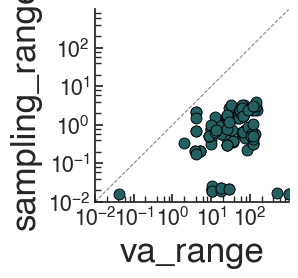

In [ ]:
# condition='WT'
list_rxn_plot=[r.id for r in prep.model.reactions if r not in prep.model.boundary and r.id not in coupled]
inv_=[r.id for r in prep.model.reactions if r.id not in list_rxn_plot]

fig,ax=plt.subplots(1,1,figsize=(2.5,2.5))
io_func.scale_rcparams(fig)

color=sns.color_palette(palette)[0] if cond=='WT' else sns.color_palette(palette)[2] 
# scatter_ranges(ax,data_bounds_flux.loc[condition].loc[list_rxn_plot],sampling_CIrange(samples_wt1,weights_wt1).loc[list_rxn_plot],condition,color=color,**cfg['settings_scatterplots'])
# scatter_ranges(ax,data_bounds_flux.loc[condition].loc[inv_],samplingrange(samples_wt1).loc[inv_],condition,color=palette[2],edgecolor='black',s=150,alpha=0.9,zorder=-10)
##sampling_percrange(samples_tm61,weights_tm61,CI=0.95)
cfg['settings_scatterplots']['s']=125*0.5
scatter_ranges(ax,prep.data_bounds_flux.loc[list_rxn_plot],y,
               cond,color=color,**cfg['settings_scatterplots'])

ax.plot([0,1],[0,1],transform=ax.transAxes,**cfg['settings_diagonal'])
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_yticks([1e-2,1e0,1e2])
ax.set_xticks([1e-2,1e0,1e2])
ax.set_xlim(1e-2,1e3)
ax.set_ylim(1e-2,1e3)
plt.rcParams['ytick.left'] = True


locmin = ticker.LogLocator(base=10.0,subs=(2.0,4.0,6.0,8.0),numticks=10)
ax.xaxis.set_minor_locator(locmin)
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
ax.yaxis.set_minor_locator(locmin)
ax.yaxis.set_minor_formatter(ticker.NullFormatter())
ax.set_xticks([1e-2,1e-1,1e0,1e1,1e2])
ax.set_yticks([1e-2,1e-1,1e0,1e1,1e2])

#set ticks towards outside

# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig4d_{cond}_scatter_va_crI.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig4d_{cond}_scatter_va_crI.svg',dpi=300,bbox_inches='tight')

write df in csv to supplementary

In [54]:
crI.to_csv(f'/home/nathan/PhD/05.Writing/13C_manuscript/Supplementary/samplingCRI{cond}.csv')